# 3. Закон Гутенберга–Рихтера и повторяемость сильных землетрясений

Закон Гутенберга–Рихтера (1944) связывает число землетрясений с их магнитудой:

$$\log_{10} N(\ge M) = a - b\,M$$

- **a** — общий уровень сейсмичности региона;
- **b** — наклон: насколько быстро убывает число событий с ростом магнитуды. Обычно b ≈ 1,
  то есть при росте магнитуды на единицу событий становится в 10 раз меньше.

b-value — физически значимый параметр: низкие значения связывают с высокими напряжениями в
земной коре, высокие — с неоднородной, ослабленной средой.

**Вопросы:** (1) выполняется ли закон на глобальном каталоге? (2) различается ли b между зонами?
(3) как часто в каждой зоне ожидать землетрясение M ≥ 7 и M ≥ 8?

Все оценки реализованы на NumPy в `src/seismic/stats.py` и проверены тестами
на синтетических данных с известными параметрами (`tests/test_stats.py`).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from seismic import analysis, db, plots, stats

plots.setup_style()
pd.set_option("display.width", 160)

events = analysis.load_events()
YEARS = events["year"].max() - events["year"].min() + 1
MC = 5.0
print(f"{len(events):,} событий за {YEARS} лет")

287,308 событий за 53 лет


## 3.1. Оценка b-value

Используется оценка максимального правдоподобия Аки (1965) с поправкой Уцу на дискретность
магнитуд (шаг ΔM = 0.1):

$$\hat b = \frac{\log_{10} e}{\bar M - (M_c - \Delta M / 2)}$$

Она устойчивее подгонки прямой методом наименьших квадратов: МНК на кумулятивной кривой
придаёт чрезмерный вес малочисленным сильным событиям. Неопределённость — перцентильный
бутстрэп (2000 повторных выборок) и аналитическая ошибка Ши–Болта.

In [2]:
mags = events["mag"].to_numpy()
above = mags[mags >= MC - 1e-9]

b, b_lo, b_hi = stats.bootstrap(above, lambda m: stats.b_value_mle(m, MC), n_boot=2000)
b_se = stats.b_value_shi_bolt_error(mags, MC, b)
a = stats.a_value(mags, MC, b, YEARS)
print(f"Событий M ≥ {MC}: {above.size:,}")
print(f"b = {b:.3f}  (95% бутстрэп: {b_lo:.3f}–{b_hi:.3f}; ошибка Ши–Болта ±{b_se:.3f})")
print(f"a = {a:.2f}  (в годовой нормировке)")

Событий M ≥ 5.0: 87,942
b = 1.080  (95% бутстрэп: 1.072–1.087; ошибка Ши–Болта ±0.004)
a = 8.62  (в годовой нормировке)


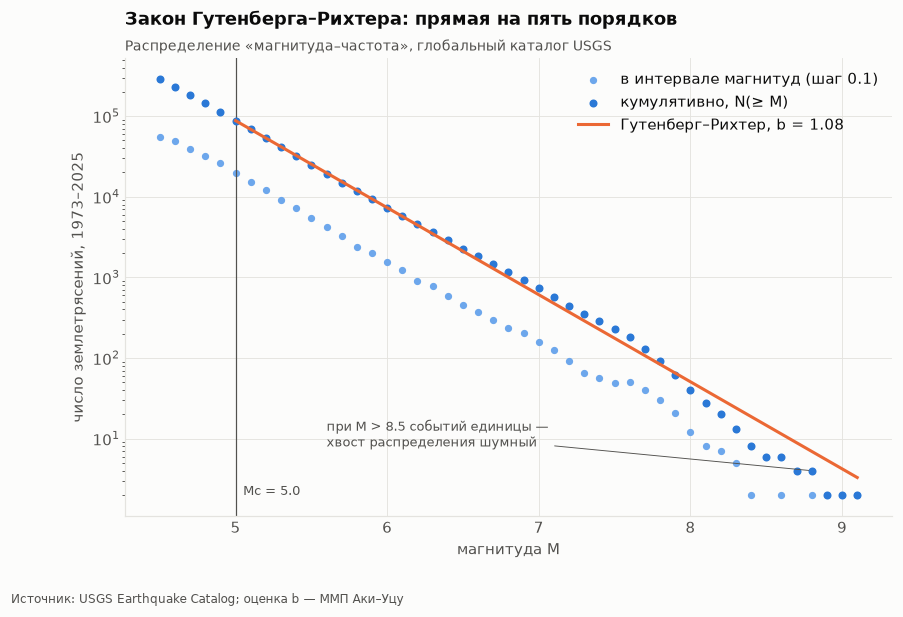

In [3]:
centers, counts, cumulative = stats.frequency_magnitude(mags)
fit_m = np.linspace(MC, 9.1, 50)
fit_n = 10 ** (a - b * fit_m) * YEARS

fig, ax = plt.subplots(figsize=(9, 5.4))
ax.scatter(centers[counts > 0], counts[counts > 0], s=14, color=plots.BLUE_RAMP[2],
           label="в интервале магнитуд (шаг 0.1)", zorder=2)
ax.scatter(centers[cumulative > 0], cumulative[cumulative > 0], s=18, color=plots.SERIES[0],
           label="кумулятивно, N(≥ M)", zorder=3)
ax.plot(fit_m, fit_n, color=plots.SERIES[1], label=f"Гутенберг–Рихтер, b = {b:.2f}", zorder=4)
ax.axvline(MC, color=plots.TEXT_MUTED, linewidth=0.8)
ax.text(MC + 0.05, 2, f"Mc = {MC}", color=plots.TEXT_MUTED, fontsize=8.5)
ax.annotate("при M > 8.5 событий единицы —\nхвост распределения шумный",
            xy=(8.8, 4), xytext=(5.6, 8), fontsize=8.5, color=plots.TEXT_MUTED,
            arrowprops=dict(arrowstyle="-", color=plots.TEXT_MUTED, linewidth=0.6))
ax.set_yscale("log")
ax.set_xlabel("магнитуда M")
ax.set_ylabel("число землетрясений, 1973–2025")
ax.grid(axis="x", visible=True)
ax.legend(loc="upper right")
ax.set_title("Закон Гутенберга–Рихтера: прямая на пять порядков")
plots.subtitle(ax, "Распределение «магнитуда–частота», глобальный каталог USGS")
plots.source_note(fig, "Источник: USGS Earthquake Catalog; оценка b — ММП Аки–Уцу")
plots.save(fig, "06_gutenberg_richter_global")
plt.show()

Кумулятивное распределение — прямая в логарифмическом масштабе от Mc до M ≈ 8.5, наклон
близок к классическому b ≈ 1. Ниже Mc точки «загибаются» вниз: это неполнота каталога, а не физика.

## 3.2. b-value по сейсмическим зонам

In [4]:
gr = analysis.gutenberg_richter_by_zone(events, mc_floor=MC, n_boot=1000)
boundary = db.query("SELECT zone_id, boundary_type FROM zones")
gr = gr.merge(boundary, on="zone_id")
gr[["zone", "boundary_type", "n", "mc", "b", "b_lo", "b_hi", "a"]].round(3)

,zone,boundary_type,n,mc,b,b_lo,b_hi,a
0,Мексика и Центральная Америка,субдукция,3217,5.0,0.892,0.865,0.922,6.246
1,Запад США и Канады,трансформная,711,5.0,0.944,0.880,1.012,5.850
2,Алеуты и Аляска,субдукция,3125,5.0,0.991,0.957,1.027,6.726
3,"Анды (Чили, Перу, Эквадор)",субдукция,5984,5.0,1.004,0.978,1.031,7.072
4,Новая Зеландия,субдукция,605,5.0,1.019,0.942,1.110,6.152
5,Карибский регион,субдукция,489,5.0,1.047,0.961,1.143,6.202
6,Новая Гвинея и Соломоновы о-ва,субдукция,9239,5.0,1.051,1.031,1.073,7.499
7,Средиземноморье и Ближний Восток,коллизия,2123,5.0,1.052,1.008,1.096,6.865
8,"Тонга, Фиджи, Вануату, Кермадек",субдукция,16574,5.0,1.055,1.040,1.071,7.773
9,"Япония, Курилы, Камчатка",субдукция,8721,5.0,1.081,1.058,1.106,7.624


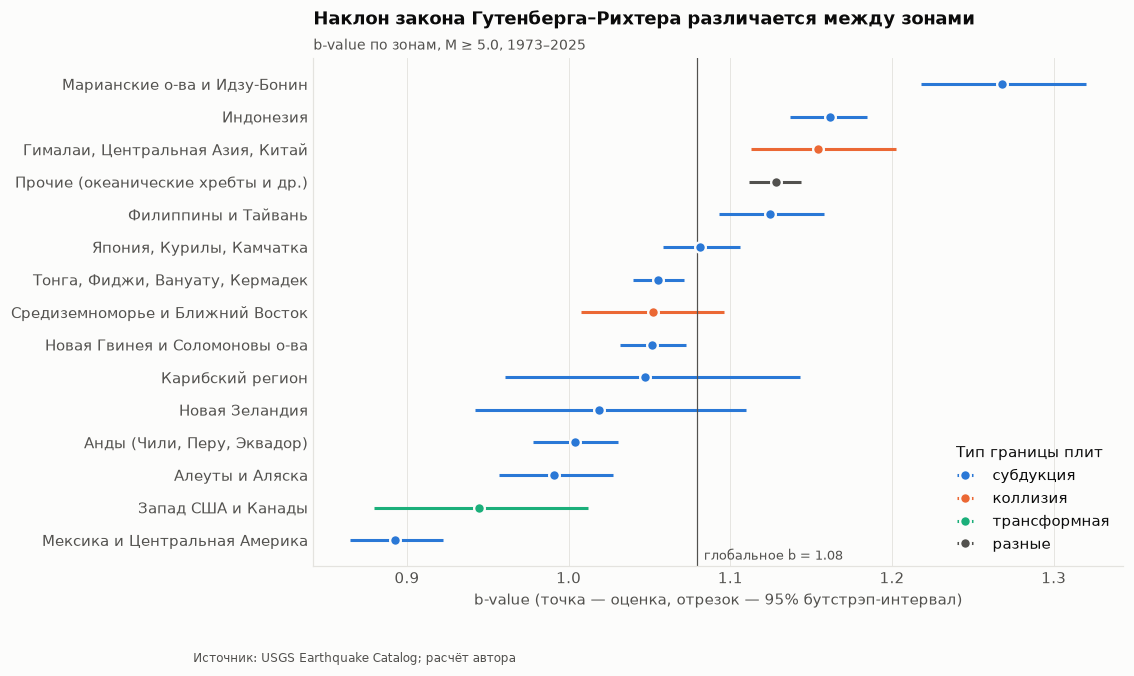

In [5]:
type_colors = {"субдукция": plots.SERIES[0], "коллизия": plots.SERIES[1],
               "трансформная": plots.SERIES[2], "разные": plots.TEXT_MUTED}
gr_sorted = gr.sort_values("b", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9.5, 6))
for btype, color in type_colors.items():
    sub = gr_sorted.loc[gr_sorted["boundary_type"] == btype]
    ax.errorbar(sub["b"], sub.index, xerr=[sub["b"] - sub["b_lo"], sub["b_hi"] - sub["b"]],
                fmt="o", color=color, markersize=7, elinewidth=2, capsize=0,
                markeredgecolor=plots.SURFACE, markeredgewidth=1.5, label=btype)
ax.axvline(b, color=plots.TEXT_MUTED, linewidth=0.8)
ax.text(b + 0.004, len(gr_sorted) - 0.4, f"глобальное b = {b:.2f}", color=plots.TEXT_MUTED, fontsize=8.5)
ax.set_yticks(gr_sorted.index, gr_sorted["zone"])
ax.set_ylim(len(gr_sorted) - 0.2, -0.8)
ax.set_xlabel("b-value (точка — оценка, отрезок — 95% бутстрэп-интервал)")
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
ax.legend(title="Тип границы плит", loc="lower right")
ax.set_title("Наклон закона Гутенберга–Рихтера различается между зонами")
plots.subtitle(ax, f"b-value по зонам, M ≥ {MC}, 1973–2025")
plots.source_note(fig, "Источник: USGS Earthquake Catalog; расчёт автора")
plots.save(fig, "07_b_value_by_zone")
plt.show()

Доверительные интервалы большинства зон не пересекаются — различия статистически значимы.

- **Низкие b (0.9–1.0)** — Мексика и Центральная Америка, запад США (разлом Сан-Андреас),
  Аляска, Анды: относительно много сильных событий на фоне слабых, что согласуется с высокими
  напряжениями на «сцепленных» границах плит.
- **Высокие b (> 1.2)** — Марианская дуга и коллизионный пояс Гималаев: в Марианской зоне
  плиты сцеплены слабо (так называемый «марианский тип» субдукции), и сильнейшие
  землетрясения здесь редки.

Оговорка: в каталоге смешаны типы магнитуд (mb для слабых событий, Mw для сильных), что может
систематически сдвигать b. Сравнение зон между собой от этого страдает меньше, чем абсолютные значения.

## 3.3. Прогноз частоты сильных событий и проверка на фактических данных

Если закон Г–Р выполняется, то по массе умеренных событий (M5–6) можно предсказать частоту
редких сильных. Проверим: сравним прогноз годовой частоты M ≥ 7 по параметрам (a, b)
с фактическим числом таких событий в каталоге.

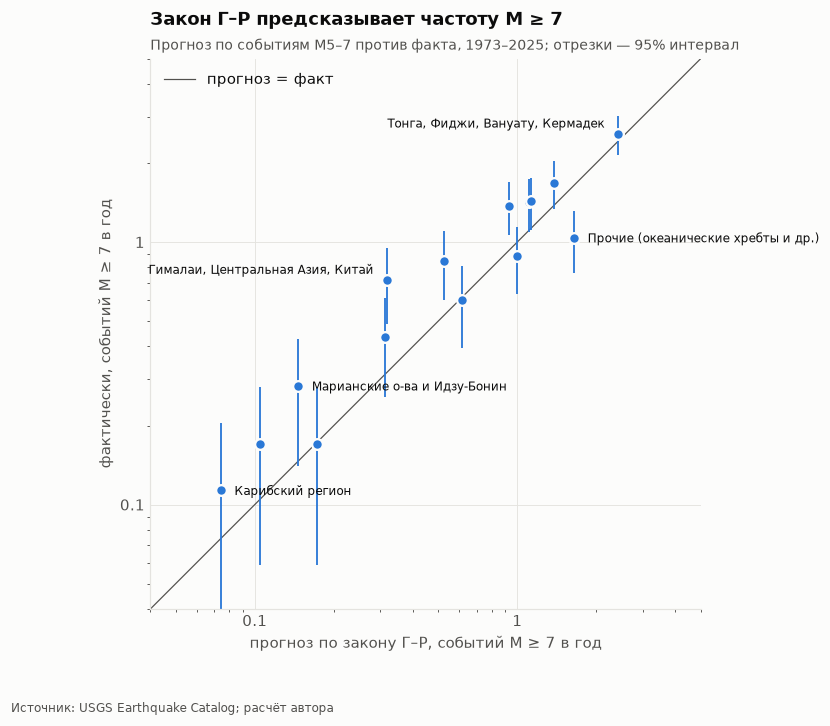

In [6]:
gr["rate_m7_gr"] = 1 / gr["return_m7_gr"]
observed_n = events.loc[events["mag"] >= 7].groupby("zone_id").size()
gr["n_m7_obs"] = gr["zone_id"].map(observed_n).fillna(0)
# 95% интервал для пуассоновской частоты: приближение ±1.96·√N
gr["obs_lo"] = np.clip(gr["n_m7_obs"] - 1.96 * np.sqrt(gr["n_m7_obs"]), 0.5, None) / YEARS
gr["obs_hi"] = (gr["n_m7_obs"] + 1.96 * np.sqrt(gr["n_m7_obs"])) / YEARS

fig, ax = plt.subplots(figsize=(7.5, 6.5))
lims = np.array([0.04, 5])
ax.plot(lims, lims, color=plots.TEXT_MUTED, linewidth=0.8, label="прогноз = факт")
ax.errorbar(gr["rate_m7_gr"], gr["m7_per_year_obs"],
            yerr=[gr["m7_per_year_obs"] - gr["obs_lo"], gr["obs_hi"] - gr["m7_per_year_obs"]],
            fmt="o", color=plots.SERIES[0], markersize=7, elinewidth=1.2, capsize=0,
            markeredgecolor=plots.SURFACE, markeredgewidth=1.5)
callouts = {"Тонга, Фиджи, Вануату, Кермадек": (-9, 4, "right"),
            "Прочие (океанические хребты и др.)": (9, -3, "left"),
            "Гималаи, Центральная Азия, Китай": (-9, 4, "right"),
            "Марианские о-ва и Идзу-Бонин": (9, -3, "left"),
            "Карибский регион": (9, -3, "left")}
for _, row in gr.loc[gr["zone"].isin(callouts)].iterrows():
    dx, dy, ha = callouts[row["zone"]]
    ax.annotate(row["zone"], (row["rate_m7_gr"], row["m7_per_year_obs"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=8, color=plots.TEXT, ha=ha)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(*lims)
ax.set_ylim(*lims)
ax.set_aspect("equal")
ax.grid(axis="x", visible=True)
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(lambda v, _: f"{v:g}")
ax.set_xlabel("прогноз по закону Г–Р, событий M ≥ 7 в год")
ax.set_ylabel("фактически, событий M ≥ 7 в год")
ax.legend(loc="upper left")
ax.set_title("Закон Г–Р предсказывает частоту M ≥ 7")
plots.subtitle(ax, "Прогноз по событиям M5–7 против факта, 1973–2025; отрезки — 95% интервал")
plots.source_note(fig, "Источник: USGS Earthquake Catalog; расчёт автора")
plots.save(fig, "08_gr_forecast_vs_observed")
plt.show()

In [7]:
residuals = np.log10(gr["m7_per_year_obs"] / gr["rate_m7_gr"])
print(f"Медианное отношение факт/прогноз: {10 ** np.median(residuals):.2f}")
print(f"Корреляция log(прогноз) и log(факт): {np.corrcoef(np.log10(gr['rate_m7_gr']), np.log10(gr['m7_per_year_obs']))[0, 1]:.2f}")

Медианное отношение факт/прогноз: 1.28
Корреляция log(прогноз) и log(факт): 0.96


Точки лежат вблизи диагонали: закон, откалиброванный на умеренных событиях, предсказывает
частоту сильных с точностью до множителя ~1.5. Систематическое отклонение — в зонах, где за
53 года произошло мало событий M ≥ 7 (широкий пуассоновский интервал), и в зонах, где
распределение «ломается» в сильной части.

## 3.4. Вероятность сильного землетрясения

Если сильные события независимы (пуассоновский поток с интенсивностью λ), вероятность хотя бы
одного события за T лет равна $P = 1 - e^{-\lambda T}$. Интенсивность λ для M ≥ 7 берём из
закона Г–Р — в разделе 3.3 он прошёл проверку на фактических данных.

In [8]:
n_m8_obs = events.loc[events["mag"] >= 8].groupby("zone_id").size()
hazard = gr[["zone", "b", "mc"]].copy()
hazard["период M≥7 (Г–Р), лет"] = gr["return_m7_gr"]
hazard["P(M≥7 за 1 год)"] = stats.poisson_exceedance(1 / gr["return_m7_gr"], 1)
hazard["P(M≥7 за 10 лет)"] = stats.poisson_exceedance(1 / gr["return_m7_gr"], 10)
hazard["период M≥8 (Г–Р), лет"] = gr["return_m8_gr"]
hazard["M≥8 по факту за 53 года"] = gr["zone_id"].map(n_m8_obs).fillna(0).astype(int)
hazard["M≥8 ожидалось по Г–Р"] = YEARS / gr["return_m8_gr"]
hazard.sort_values("P(M≥7 за 1 год)", ascending=False).round(2).reset_index(drop=True)

,zone,b,mc,"период M≥7 (Г–Р), лет",P(M≥7 за 1 год),P(M≥7 за 10 лет),"период M≥8 (Г–Р), лет",M≥8 по факту за 53 года,M≥8 ожидалось по Г–Р
0,"Тонга, Фиджи, Вануату, Кермадек",1.06,5.0,0.41,0.91,1.00,4.69,6,11.30
1,Прочие (океанические хребты и др.),1.13,5.0,0.61,0.81,1.00,8.18,4,6.48
2,Новая Гвинея и Соломоновы о-ва,1.05,5.0,0.73,0.75,1.00,8.19,3,6.47
3,"Япония, Курилы, Камчатка",1.08,5.0,0.88,0.68,1.00,10.67,7,4.97
4,"Анды (Чили, Перу, Эквадор)",1.00,5.0,0.90,0.67,1.00,9.09,9,5.83
5,Мексика и Центральная Америка,0.89,5.0,1.00,0.63,1.00,7.84,3,6.76
6,Индонезия,1.16,5.0,1.07,0.61,1.00,15.56,6,3.41
7,Алеуты и Аляска,0.99,5.0,1.63,0.46,1.00,15.95,2,3.32
8,Филиппины и Тайвань,1.12,5.0,1.90,0.41,0.99,25.34,0,2.09
9,"Гималаи, Центральная Азия, Китай",1.15,5.0,3.13,0.27,0.96,44.64,0,1.19


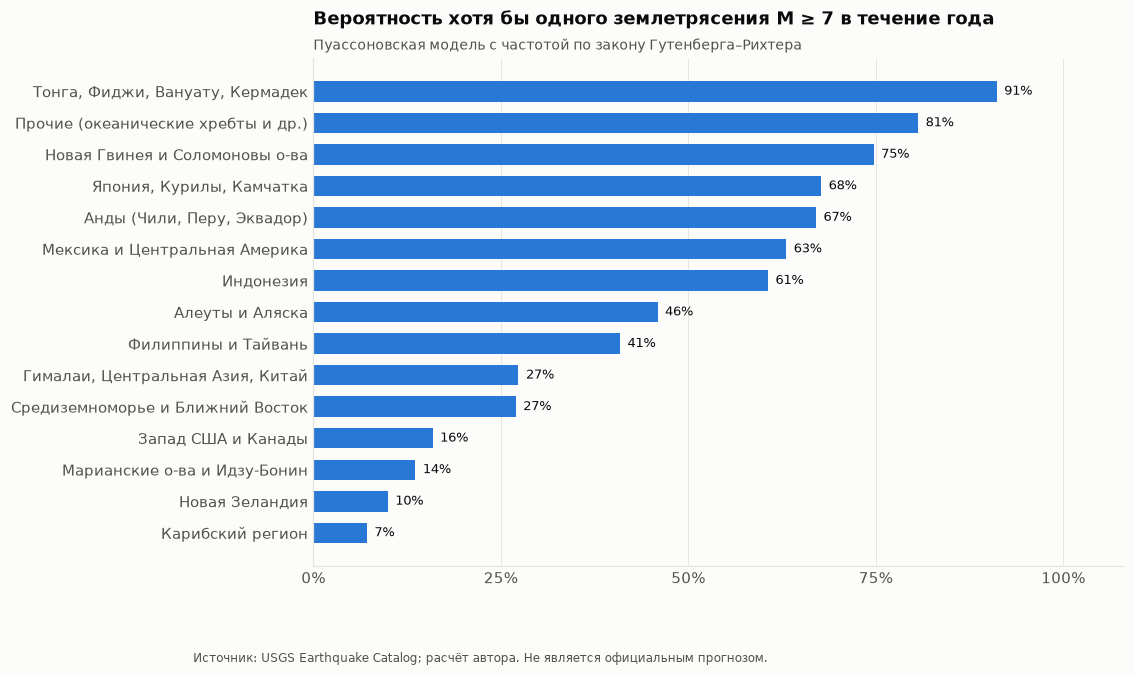

In [9]:
h = hazard.sort_values("P(M≥7 за 1 год)")
fig, ax = plt.subplots(figsize=(9.5, 6))
ax.barh(h["zone"], h["P(M≥7 за 1 год)"] * 100, color=plots.SERIES[0], height=0.65)
for i, v in enumerate(h["P(M≥7 за 1 год)"] * 100):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8.5, color=plots.TEXT)
ax.set_xlim(0, 108)
ax.set_xticks(range(0, 101, 25), [f"{x}%" for x in range(0, 101, 25)])
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_title("Вероятность хотя бы одного землетрясения M ≥ 7 в течение года")
plots.subtitle(ax, "Пуассоновская модель с частотой по закону Гутенберга–Рихтера")
plots.source_note(fig, "Источник: USGS Earthquake Catalog; расчёт автора. Не является официальным прогнозом.")
plots.save(fig, "09_probability_m7_year")
plt.show()

**Ограничение экстраполяции.** Для M ≥ 8 закон Г–Р в ряде зон предсказывает заметно больше
событий, чем наблюдалось (сравните два последних столбца таблицы). Причина — у каждой зоны есть
физический предел магнитуды Mmax, зависящий от длины и ширины разлома: в Центральной Америке
или в Гималаях нет протяжённых мегаразломов, способных дать M9. Поэтому для оценки самых сильных
событий используют усечённое распределение Г–Р, а вероятности M ≥ 8 по чистому закону — это
верхняя граница.


## 3.5. Независимы ли сильные землетрясения?

Пуассоновская модель предполагает независимость событий. Тогда интервалы между ними
распределены экспоненциально, а коэффициент вариации CV = σ/μ ≈ 1. Если сильные события
группируются (афтершоки, «дуплеты»), CV > 1 и коротких интервалов больше, чем ожидается.

In [10]:
gaps = db.query("05_inter_event_m7", {"min_mag": 7.0})["days_since_prev"].dropna().to_numpy()
cv = stats.coefficient_of_variation(gaps)
mean_gap = gaps.mean()

# статистика Колмогорова–Смирнова против экспоненты — вручную на NumPy
x = np.sort(gaps)
ecdf = np.arange(1, x.size + 1) / x.size
model_cdf = 1 - np.exp(-x / mean_gap)
ks = np.max(np.maximum(np.abs(ecdf - model_cdf), np.abs(ecdf - 1 / x.size - model_cdf)))
ks_crit = 1.36 / np.sqrt(x.size)  # 5% критическое значение (без учёта оценки параметра)

short = np.mean(gaps < 1)
print(f"Событий M ≥ 7: {gaps.size + 1}, средний интервал {mean_gap:.1f} сут.")
print(f"CV = {cv:.2f}; KS = {ks:.3f} (критическое ≈ {ks_crit:.3f})")
print(f"Интервалов короче суток: {short:.1%}, ожидалось при Пуассоне: {1 - np.exp(-1 / mean_gap):.1%}")

Событий M ≥ 7: 729, средний интервал 26.5 сут.
CV = 1.08; KS = 0.048 (критическое ≈ 0.050)
Интервалов короче суток: 7.7%, ожидалось при Пуассоне: 3.7%


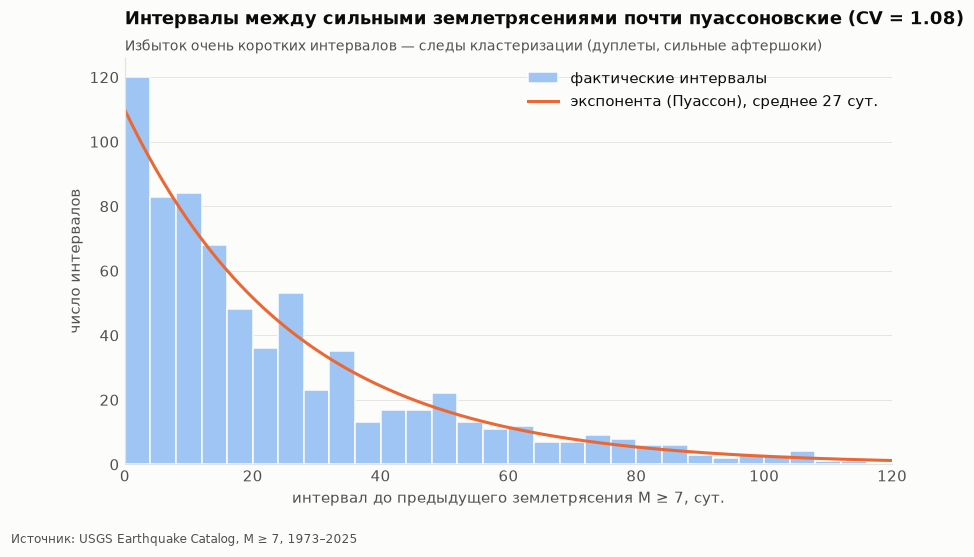

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.8))
bins = np.arange(0, 121, 4)
ax.hist(gaps, bins=bins, color=plots.BLUE_RAMP[1], edgecolor=plots.SURFACE, linewidth=1,
        label="фактические интервалы")
grid = np.linspace(0, 120, 300)
ax.plot(grid, gaps.size * 4 * np.exp(-grid / mean_gap) / mean_gap, color=plots.SERIES[1],
        label=f"экспонента (Пуассон), среднее {mean_gap:.0f} сут.")
ax.set_xlim(0, 120)
ax.set_xlabel("интервал до предыдущего землетрясения M ≥ 7, сут.")
ax.set_ylabel("число интервалов")
ax.legend(loc="upper right")
ax.set_title(f"Интервалы между сильными землетрясениями почти пуассоновские (CV = {cv:.2f})")
plots.subtitle(ax, "Избыток очень коротких интервалов — следы кластеризации (дуплеты, сильные афтершоки)")
plots.source_note(fig, "Источник: USGS Earthquake Catalog, M ≥ 7, 1973–2025")
plots.save(fig, "10_inter_event_times")
plt.show()

**Выводы ноутбука:**
1. Закон Гутенберга–Рихтера выполняется на глобальном каталоге (b = 1.08) в диапазоне M5–8.5.
2. b-value различается между зонами статистически значимо (от 0.89 до 1.27).
3. Закон, откалиброванный на умеренных событиях, предсказывает частоту M ≥ 7 с точностью до множителя ~1.5
   (корреляция 0.96), но переоценивает M ≥ 8 там, где размер разломов ограничивает Mmax.
4. Сильные землетрясения в глобальном масштабе близки к пуассоновскому потоку, но с заметной
   кластеризацией на коротких интервалах — поэтому пуассоновские вероятности следует понимать
   как нижнюю оценку риска в первые дни после сильного толчка.